C:\Users\VEDANT\AppData\Local\Temp\ipykernel_18036\2379709503.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date, progress=False)["Close"]


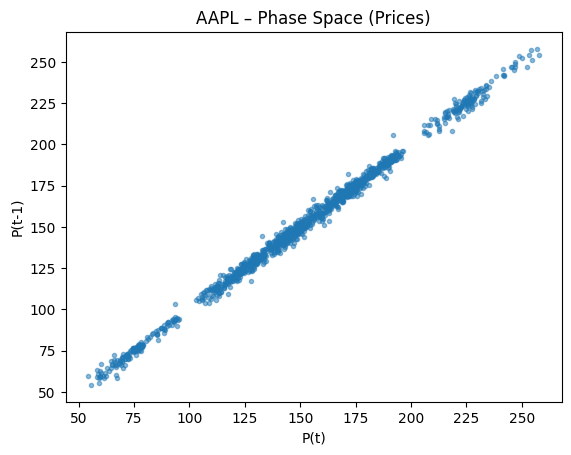

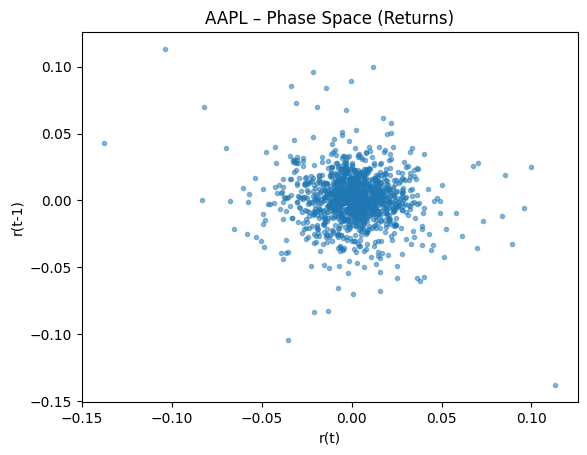

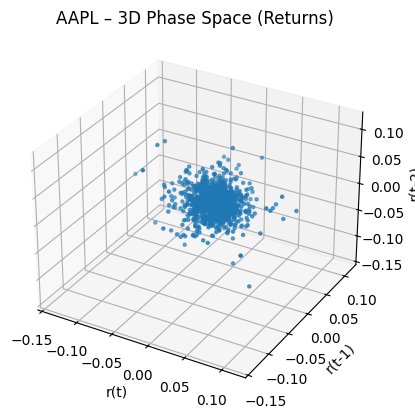

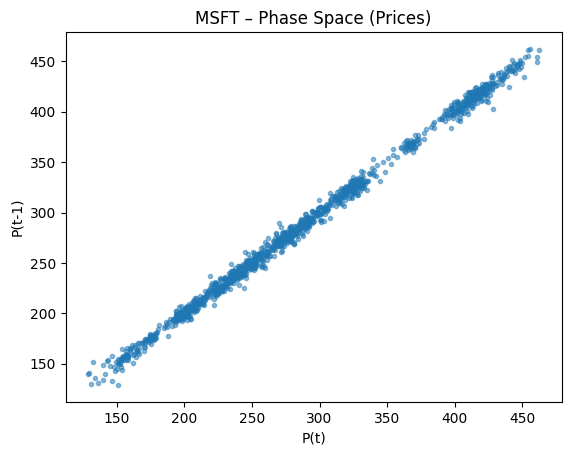

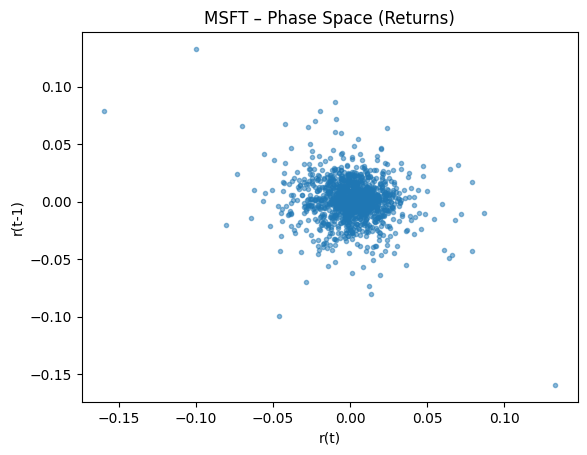

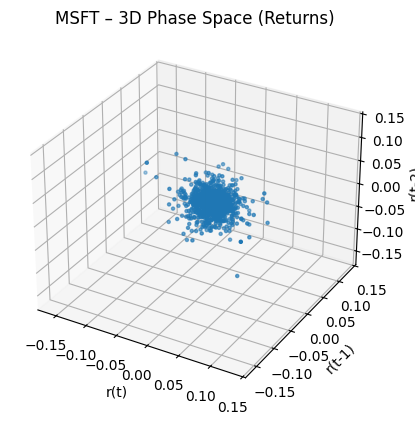

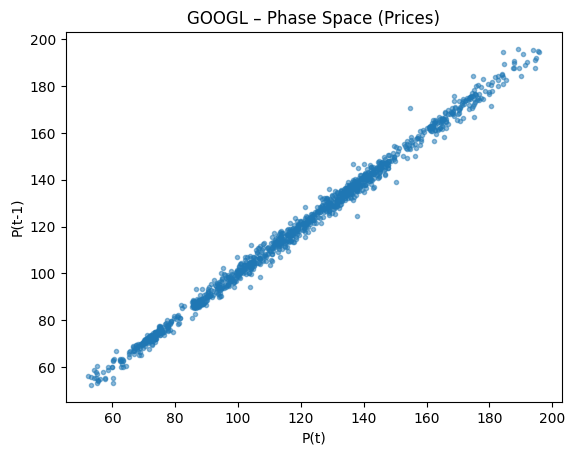

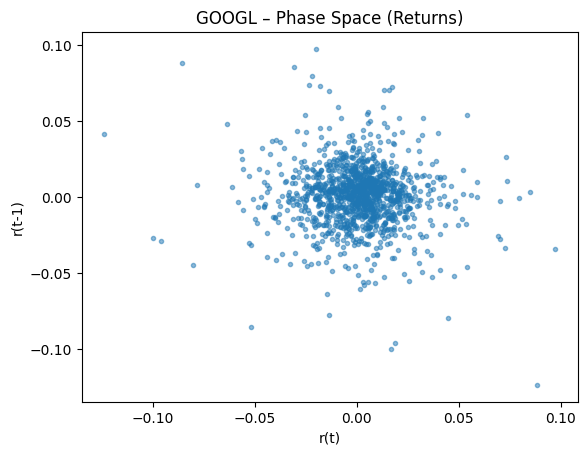

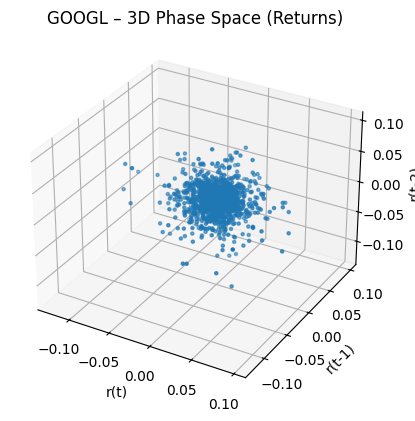

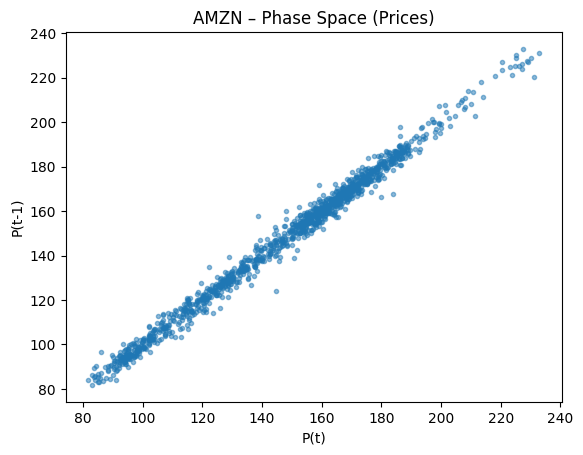

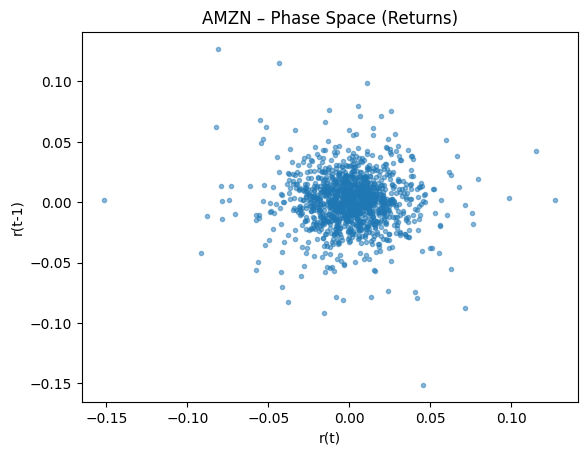

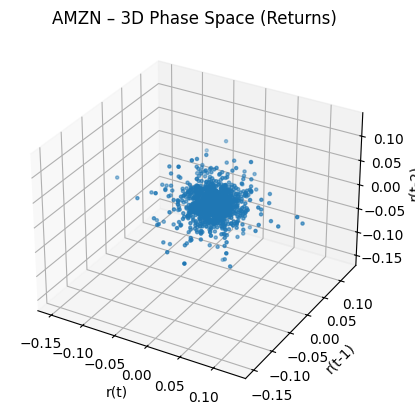

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf

# --------------------------------
# 1. Configuration
# --------------------------------
tickers = ["AAPL", "MSFT", "GOOGL", "AMZN"]
start_date = "2020-01-01"
end_date = "2025-01-01"
embedding_dim = 3
max_lag = 50

# --------------------------------
# 2. Helper functions
# --------------------------------
def choose_tau(series, max_lag=50):
    acf_vals = acf(series, nlags=max_lag, fft=True)
    for i in range(1, len(acf_vals)):
        if acf_vals[i] < 1 / np.e:
            return i
    return 1

def takens_embedding(series, m, tau):
    n = len(series)
    embedded = np.empty((n - (m - 1) * tau, m))
    for i in range(m):
        embedded[:, i] = series[i * tau : n - (m - 1) * tau + i * tau]
    return embedded

# --------------------------------
# 3. Download data
# --------------------------------
data = yf.download(tickers, start=start_date, end=end_date, progress=False)["Close"]

# --------------------------------
# 4. Loop over stocks
# --------------------------------
for ticker in tickers:
    prices = data[ticker].dropna()
    returns = np.log(prices).diff().dropna()

    # choose delays
    tau_price = choose_tau(prices.values, max_lag)
    tau_return = choose_tau(returns.values, max_lag)

    # embeddings
    X_price = takens_embedding(prices.values, embedding_dim, tau_price)
    X_return = takens_embedding(returns.values, embedding_dim, tau_return)

    # --------------------------------
    # 5. Plot price phase space (2D)
    # --------------------------------
    plt.figure()
    plt.plot(X_price[:, 0], X_price[:, 1], ".", alpha=0.5)
    plt.xlabel("P(t)")
    plt.ylabel(f"P(t-{tau_price})")
    plt.title(f"{ticker} – Phase Space (Prices)")
    plt.show()

    # --------------------------------
    # 6. Plot return phase space (2D)
    # --------------------------------
    plt.figure()
    plt.plot(X_return[:, 0], X_return[:, 1], ".", alpha=0.5)
    plt.xlabel("r(t)")
    plt.ylabel(f"r(t-{tau_return})")
    plt.title(f"{ticker} – Phase Space (Returns)")
    plt.show()

    # --------------------------------
    # 7. Plot return phase space (3D)
    # --------------------------------
    fig = plt.figure()
    ax = fig.add_subplot(projection="3d")
    ax.scatter(
        X_return[:, 0],
        X_return[:, 1],
        X_return[:, 2],
        s=5
    )
    ax.set_xlabel("r(t)")
    ax.set_ylabel(f"r(t-{tau_return})")
    ax.set_zlabel(f"r(t-{2 * tau_return})")
    ax.set_title(f"{ticker} – 3D Phase Space (Returns)")
    plt.show()



Processing AAPL...
  Data points: 1258 prices, 1257 returns
  Price tau - ACF: 5, MI: 31, Selected: 18
  Return tau - ACF: 3, MI: 3, Selected: 3
  Embedding dimensions - Prices: 3, Returns: 3


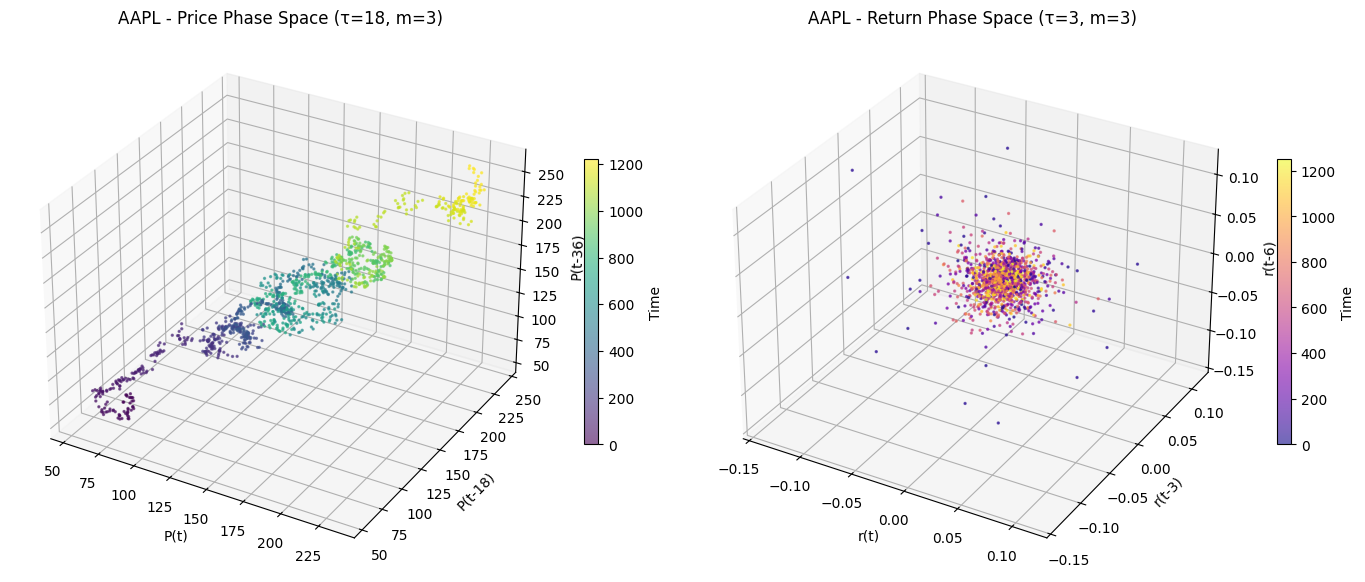


Processing MSFT...
  Data points: 1258 prices, 1257 returns
  Price tau - ACF: 5, MI: 25, Selected: 15
  Return tau - ACF: 3, MI: 3, Selected: 3
  Embedding dimensions - Prices: 3, Returns: 3


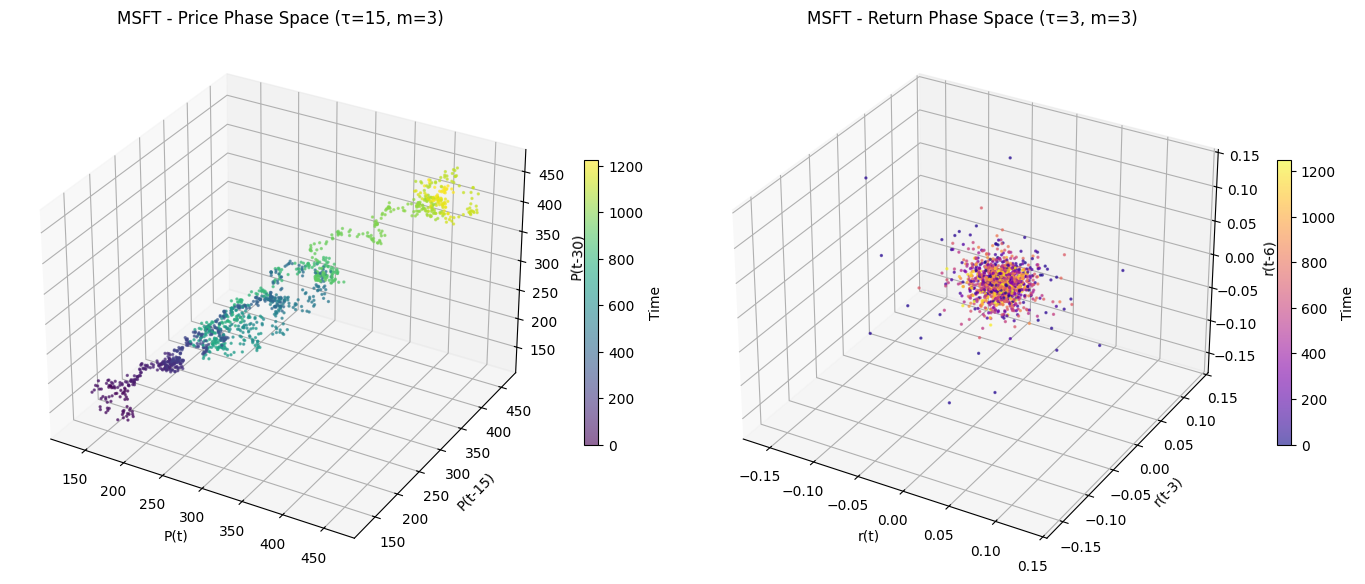


Processing GOOGL...
  Data points: 1258 prices, 1257 returns
  Price tau - ACF: 5, MI: 21, Selected: 13
  Return tau - ACF: 3, MI: 3, Selected: 3
  Embedding dimensions - Prices: 3, Returns: 3


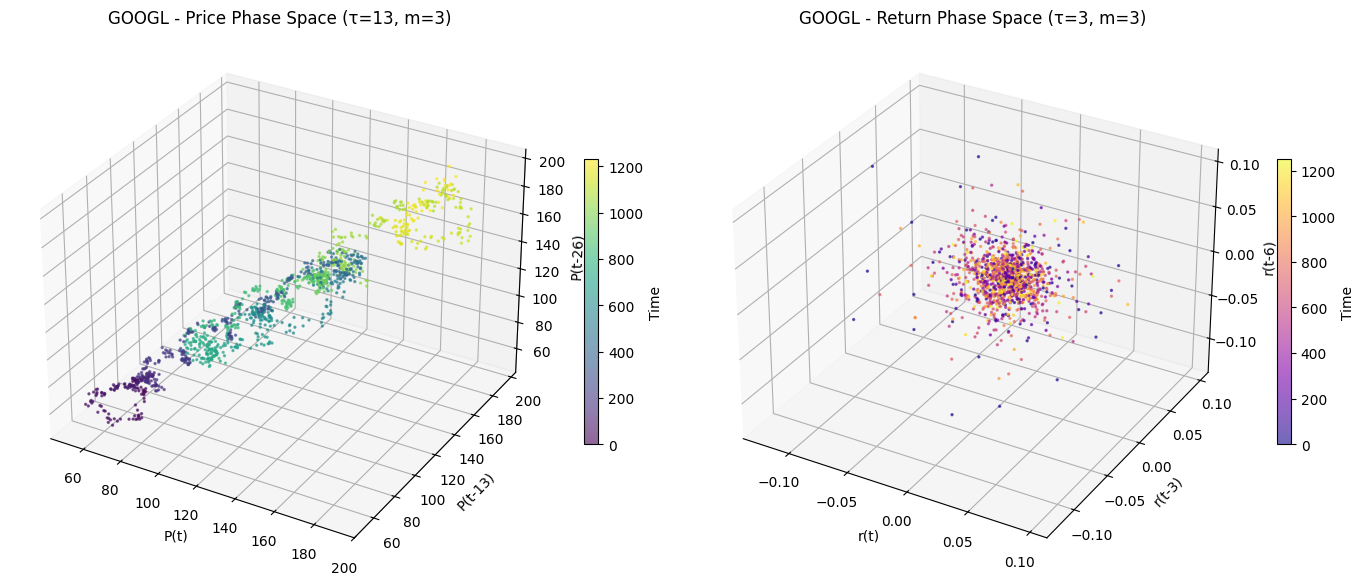


Processing TSLA...
  Data points: 1258 prices, 1257 returns
  Price tau - ACF: 5, MI: 25, Selected: 15
  Return tau - ACF: 3, MI: 2, Selected: 2
  Embedding dimensions - Prices: 3, Returns: 3


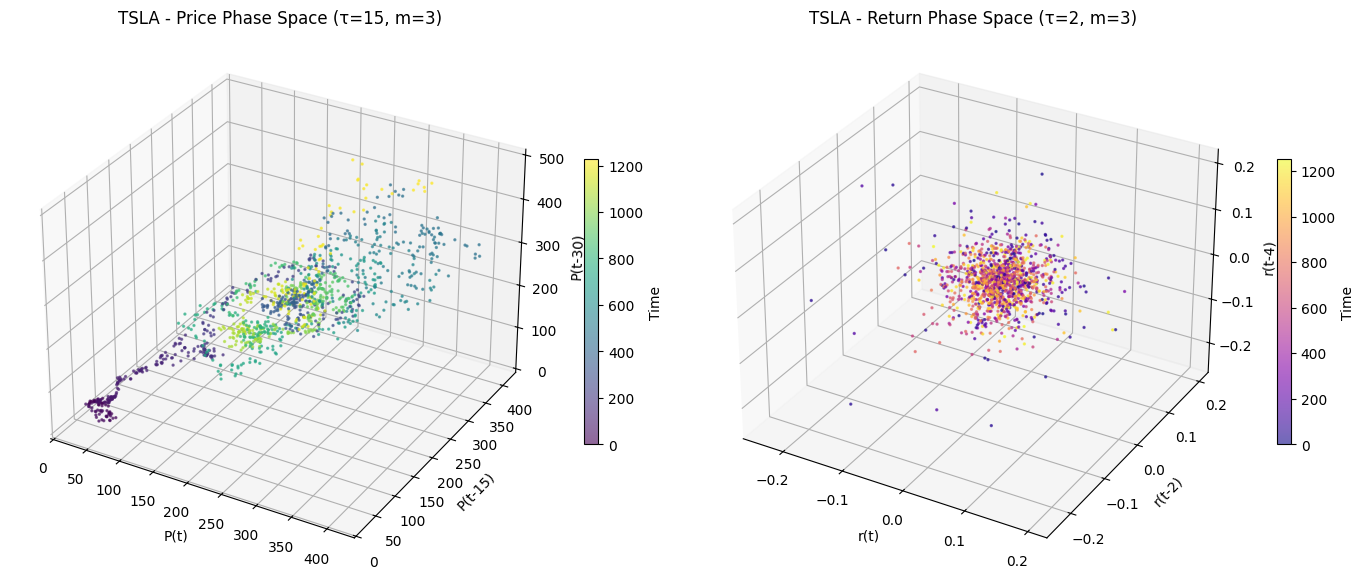


Processing AMZN...
  Data points: 1258 prices, 1257 returns
  Price tau - ACF: 5, MI: 16, Selected: 10
  Return tau - ACF: 3, MI: 4, Selected: 3
  Embedding dimensions - Prices: 3, Returns: 3


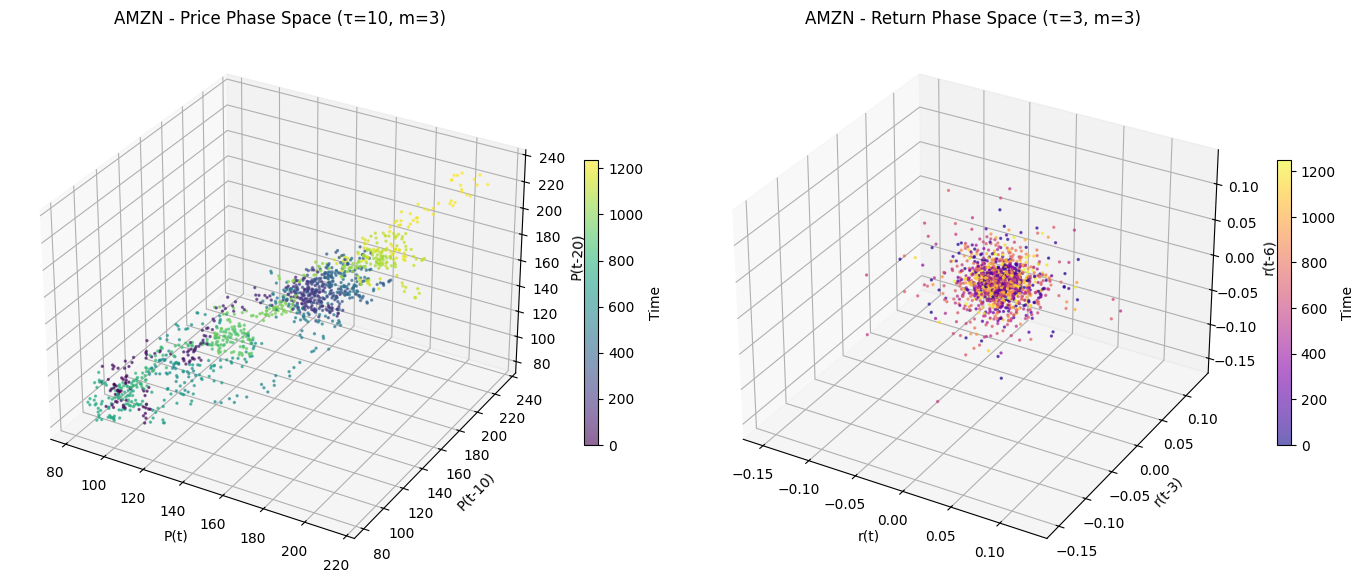


Processing complete!


In [2]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist
from statsmodels.tsa.stattools import acf

tickers = ["AAPL", "MSFT", "GOOGL", "TSLA", "AMZN"]
start = "2020-01-01"
end = "2025-01-01"
m = 3
max_lag = 50

def mutual_information_delay(series, max_lag=50):
    series = np.array(series).flatten()
    series = (series - np.mean(series)) / np.std(series)
    n_bins = max(10, int(np.sqrt(len(series) / 5)))
    
    def mi(x, y, bins):
        hist_2d, _, _ = np.histogram2d(x, y, bins=bins)
        pxy = hist_2d / (np.sum(hist_2d) + 1e-10)
        px = np.sum(pxy, axis=1)
        py = np.sum(pxy, axis=0)
        px_py = px[:, None] * py[None, :] + 1e-10
        nzs = pxy > 0
        return np.sum(pxy[nzs] * np.log(pxy[nzs] / px_py[nzs]))
    
    mi_values = []
    for lag in range(1, min(max_lag, len(series)//4)):
        if lag >= len(series):
            break
        mi_val = mi(series[:-lag], series[lag:], n_bins)
        mi_values.append(mi_val)
    
    if len(mi_values) < 3:
        return 5
    
    mi_array = np.array(mi_values)
    
    local_minima = []
    for i in range(1, len(mi_array)-1):
        if mi_array[i] < mi_array[i-1] and mi_array[i] < mi_array[i+1]:
            local_minima.append(i + 1)
    
    if len(local_minima) > 0:
        return local_minima[0]
    
    first_min = np.argmin(mi_array) + 1
    return max(3, first_min)

def choose_tau_acf(series, max_lag=50):
    series = np.array(series).flatten()
    series = series[~np.isnan(series)]
    series = series[~np.isinf(series)]
    
    if len(series) < 10:
        return 5
    
    try:
        nlags = min(max_lag, len(series)//4)
        acf_vals = acf(series, nlags=nlags, fft=True)
        
        threshold = 1/np.e
        for i in range(1, len(acf_vals)):
            if acf_vals[i] < threshold:
                return max(3, i)
        
        zero_crossings = []
        for i in range(1, len(acf_vals)):
            if acf_vals[i] * acf_vals[i-1] < 0:
                zero_crossings.append(i)
        
        if len(zero_crossings) > 0:
            return max(3, zero_crossings[0])
            
    except:
        return 5
    
    return 5

def false_nearest_neighbors(series, tau, max_dim=10):
    def embed(data, dimension, delay):
        n = len(data) - (dimension - 1) * delay
        return np.array([data[i:i + dimension * delay:delay] for i in range(n)])
    
    rtol = 15.0
    atol = 2.0
    
    for dim in range(1, max_dim):
        X1 = embed(series, dim, tau)
        X2 = embed(series, dim + 1, tau)
        
        if len(X1) < 2 or len(X2) < 2:
            return dim
        
        false_neighbors = 0
        
        for i in range(min(100, len(X1))):
            distances = np.sqrt(np.sum((X1 - X1[i])**2, axis=1))
            distances[i] = np.inf
            nearest_idx = np.argmin(distances)
            
            if nearest_idx >= len(X2):
                continue
                
            d1 = distances[nearest_idx]
            d2 = np.sqrt(np.sum((X2[i] - X2[nearest_idx])**2))
            
            if d1 > 0 and (d2 / d1 > rtol or d2 > atol * np.std(series)):
                false_neighbors += 1
        
        fnn_ratio = false_neighbors / min(100, len(X1))
        if fnn_ratio < 0.1:
            return dim
    
    return max_dim

def takens_embedding(series, m, tau):
    n = len(series)
    if n < (m-1)*tau + 1:
        return None
    return np.column_stack(
        [series[i*tau : n-(m-1)*tau+i*tau] for i in range(m)]
    )

for ticker in tickers:
    try:
        print(f"\nProcessing {ticker}...")
        data = yf.download(ticker, start=start, end=end, progress=False, auto_adjust=True)
        
        if data.empty or 'Close' not in data.columns:
            print(f"Skipping {ticker}: no data available")
            continue
        
        prices = data['Close'].values
        prices = prices[~np.isnan(prices)]
        
        if len(prices) < 100:
            print(f"Skipping {ticker}: insufficient data ({len(prices)} points)")
            continue
        
        log_prices = np.log(prices)
        returns = np.diff(log_prices)
        
        print(f"  Data points: {len(prices)} prices, {len(returns)} returns")
        
        tau_p_acf = choose_tau_acf(prices)
        tau_r_acf = choose_tau_acf(returns)
        
        tau_p_mi = mutual_information_delay(prices, max_lag)
        tau_r_mi = mutual_information_delay(returns, max_lag)
        
        tau_p = int(np.median([tau_p_acf, tau_p_mi]))
        tau_r = int(np.median([tau_r_acf, tau_r_mi]))
        
        print(f"  Price tau - ACF: {tau_p_acf}, MI: {tau_p_mi}, Selected: {tau_p}")
        print(f"  Return tau - ACF: {tau_r_acf}, MI: {tau_r_mi}, Selected: {tau_r}")
        
        m_optimal_p = false_nearest_neighbors(prices, tau_p, max_dim=10)
        m_optimal_r = false_nearest_neighbors(returns, tau_r, max_dim=10)
        
        m_p = max(3, min(m, m_optimal_p))
        m_r = max(3, min(m, m_optimal_r))
        
        print(f"  Embedding dimensions - Prices: {m_p}, Returns: {m_r}")
        
        Xp = takens_embedding(prices, m_p, tau_p)
        Xr = takens_embedding(returns, m_r, tau_r)
        
        if Xp is None or Xr is None or len(Xp) == 0 or len(Xr) == 0:
            print(f"  Skipping {ticker}: embedding failed")
            continue
        
        if Xp.shape[1] < 3 or Xr.shape[1] < 3:
            print(f"  Skipping {ticker}: insufficient dimensions")
            continue
        
        fig = plt.figure(figsize=(14, 6))
        
        ax1 = fig.add_subplot(121, projection="3d")
        scatter1 = ax1.scatter(Xp[:,0], Xp[:,1], Xp[:,2], 
                               c=np.arange(len(Xp)), cmap='viridis', s=2, alpha=0.6)
        ax1.set_title(f"{ticker} - Price Phase Space (τ={tau_p}, m={m_p})")
        ax1.set_xlabel("P(t)")
        ax1.set_ylabel(f"P(t-{tau_p})")
        ax1.set_zlabel(f"P(t-{2*tau_p})")
        plt.colorbar(scatter1, ax=ax1, label='Time', shrink=0.5)
        
        ax2 = fig.add_subplot(122, projection="3d")
        scatter2 = ax2.scatter(Xr[:,0], Xr[:,1], Xr[:,2], 
                               c=np.arange(len(Xr)), cmap='plasma', s=2, alpha=0.6)
        ax2.set_title(f"{ticker} - Return Phase Space (τ={tau_r}, m={m_r})")
        ax2.set_xlabel("r(t)")
        ax2.set_ylabel(f"r(t-{tau_r})")
        ax2.set_zlabel(f"r(t-{2*tau_r})")
        plt.colorbar(scatter2, ax=ax2, label='Time', shrink=0.5)
        
        plt.tight_layout()
        plt.show()
        
    except Exception as e:
        print(f"Error processing {ticker}: {e}")
        import traceback
        traceback.print_exc()
        continue

print("\nProcessing complete!")


Processing AAPL
Data points: 1258 prices, 1257 returns

--- Time Lag Estimation ---
Prices  - ACF: 1, AMI: 31
Returns - ACF: 1, AMI: 3

--- Embedding Dimension Estimation ---
Prices  - Optimal embedding dimension: 3
Returns - Optimal embedding dimension: 15

--- Building Takens Vectors ---
Price Takens matrix shape: (1196, 3)
Return Takens matrix shape: (1251, 3)

--- Correlation Dimension Estimation ---
Price correlation dimension: 2.496
Return correlation dimension: 2.622


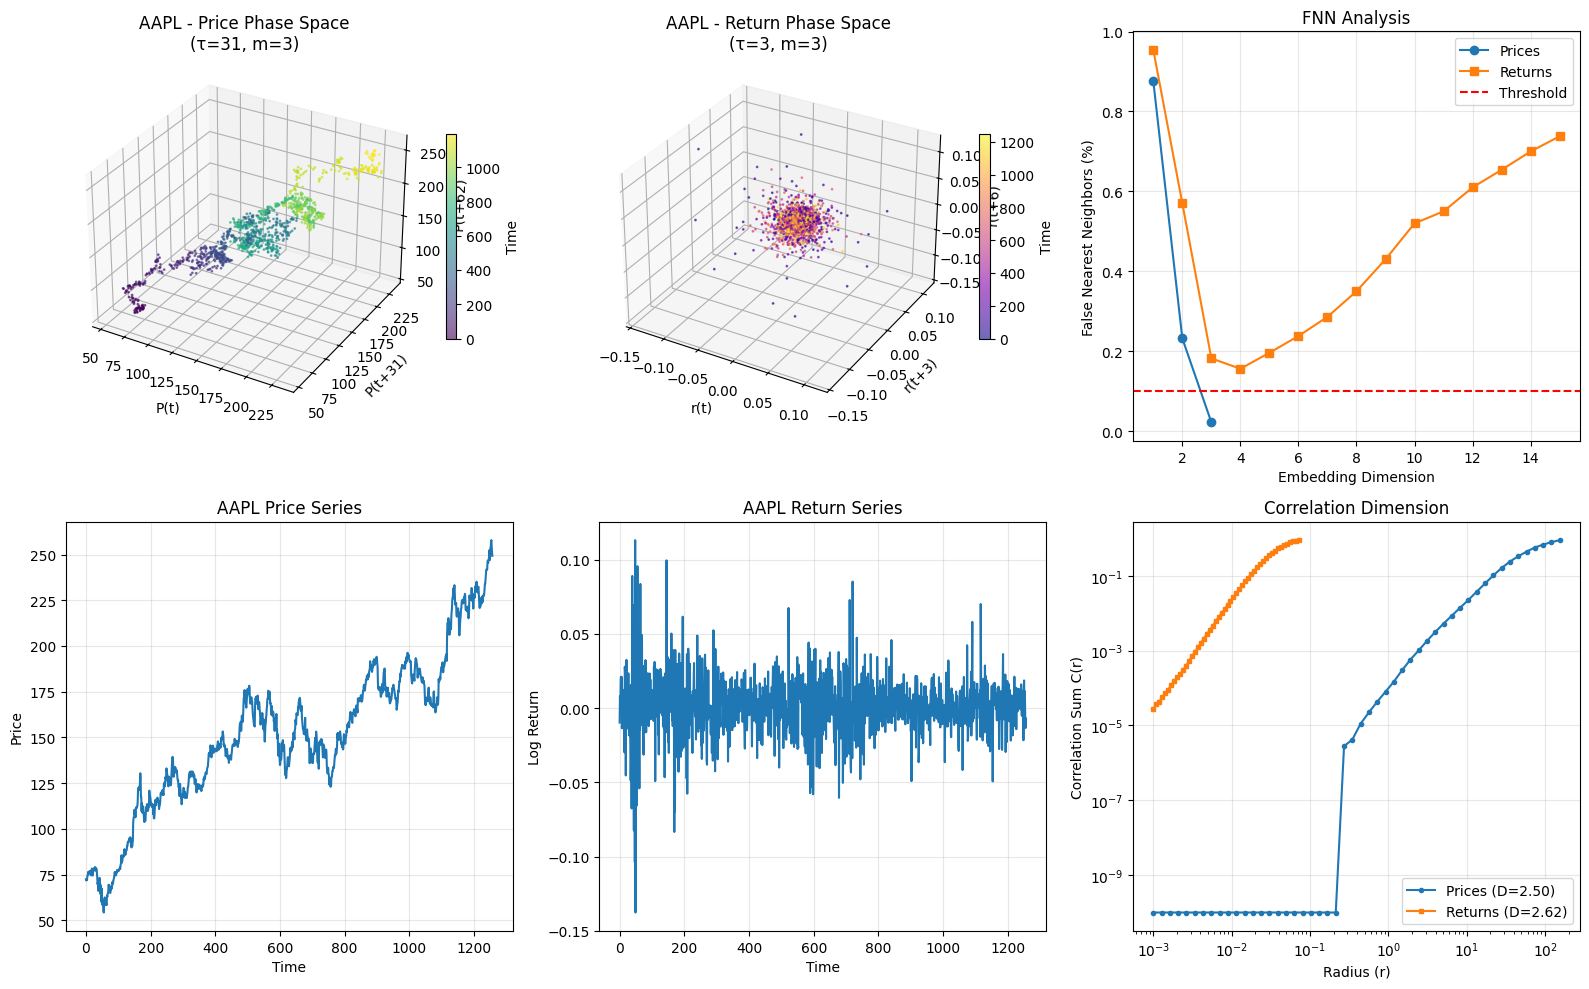


Processing MSFT
Data points: 1258 prices, 1257 returns

--- Time Lag Estimation ---
Prices  - ACF: 1, AMI: 25
Returns - ACF: 1, AMI: 3

--- Embedding Dimension Estimation ---
Prices  - Optimal embedding dimension: 3
Returns - Optimal embedding dimension: 15

--- Building Takens Vectors ---
Price Takens matrix shape: (1208, 3)
Return Takens matrix shape: (1251, 3)

--- Correlation Dimension Estimation ---
Price correlation dimension: 2.362
Return correlation dimension: 2.593


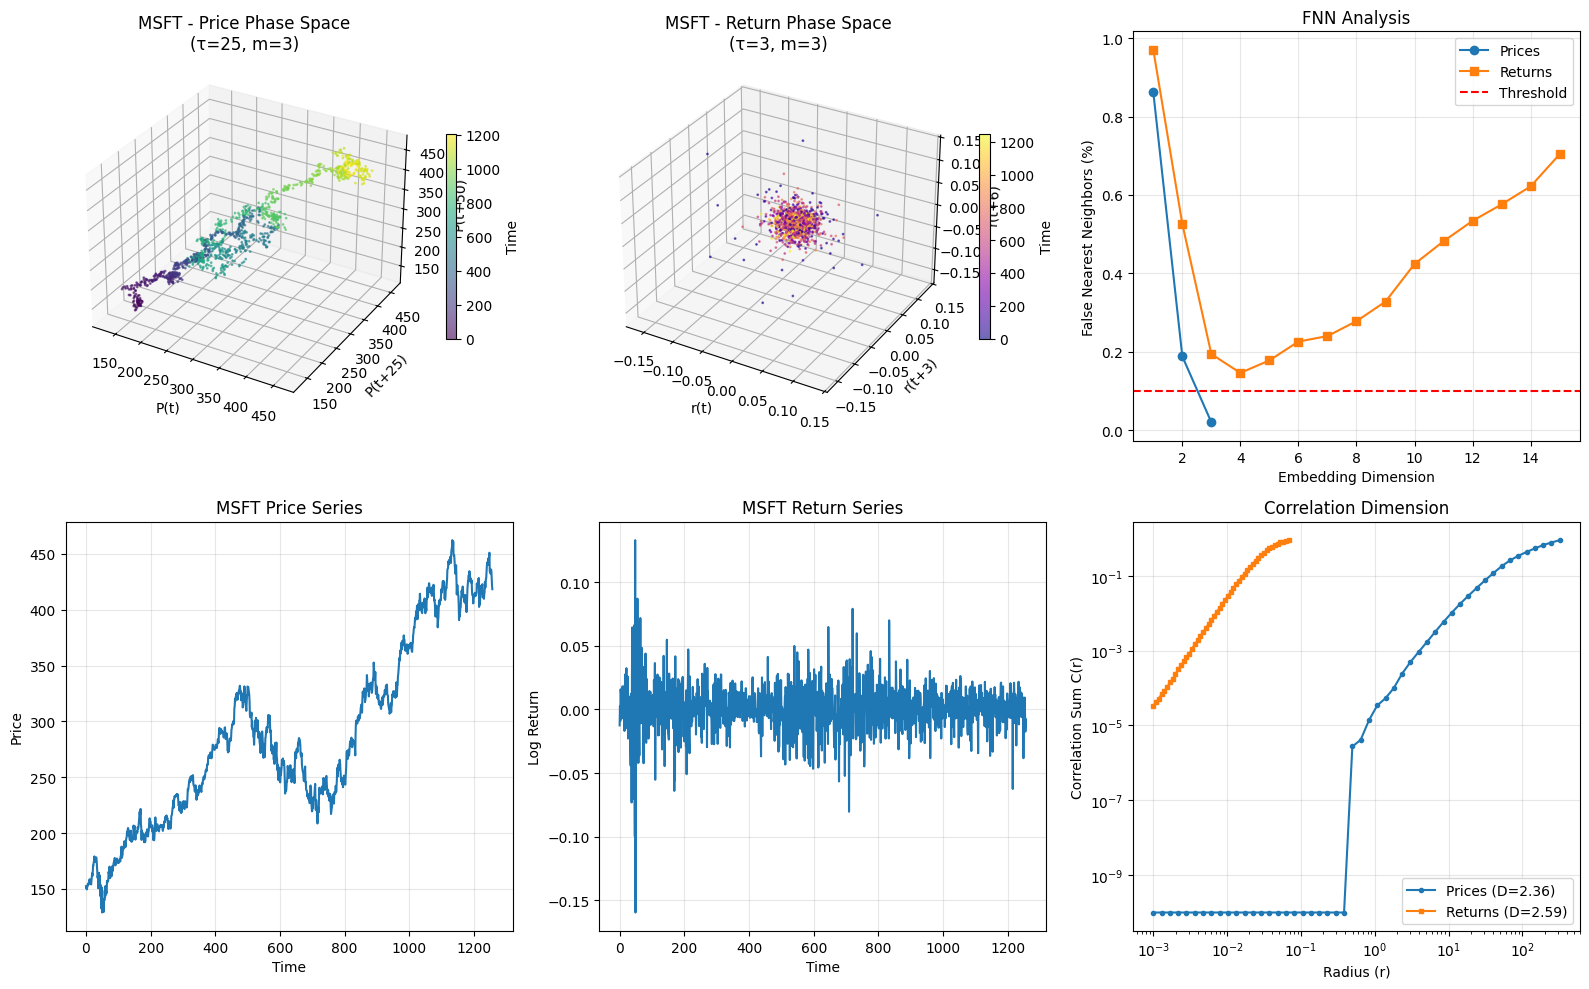


Processing GOOGL
Data points: 1258 prices, 1257 returns

--- Time Lag Estimation ---
Prices  - ACF: 1, AMI: 21
Returns - ACF: 1, AMI: 3

--- Embedding Dimension Estimation ---
Prices  - Optimal embedding dimension: 3
Returns - Optimal embedding dimension: 15

--- Building Takens Vectors ---
Price Takens matrix shape: (1216, 3)
Return Takens matrix shape: (1251, 3)

--- Correlation Dimension Estimation ---
Price correlation dimension: 2.519
Return correlation dimension: 2.536


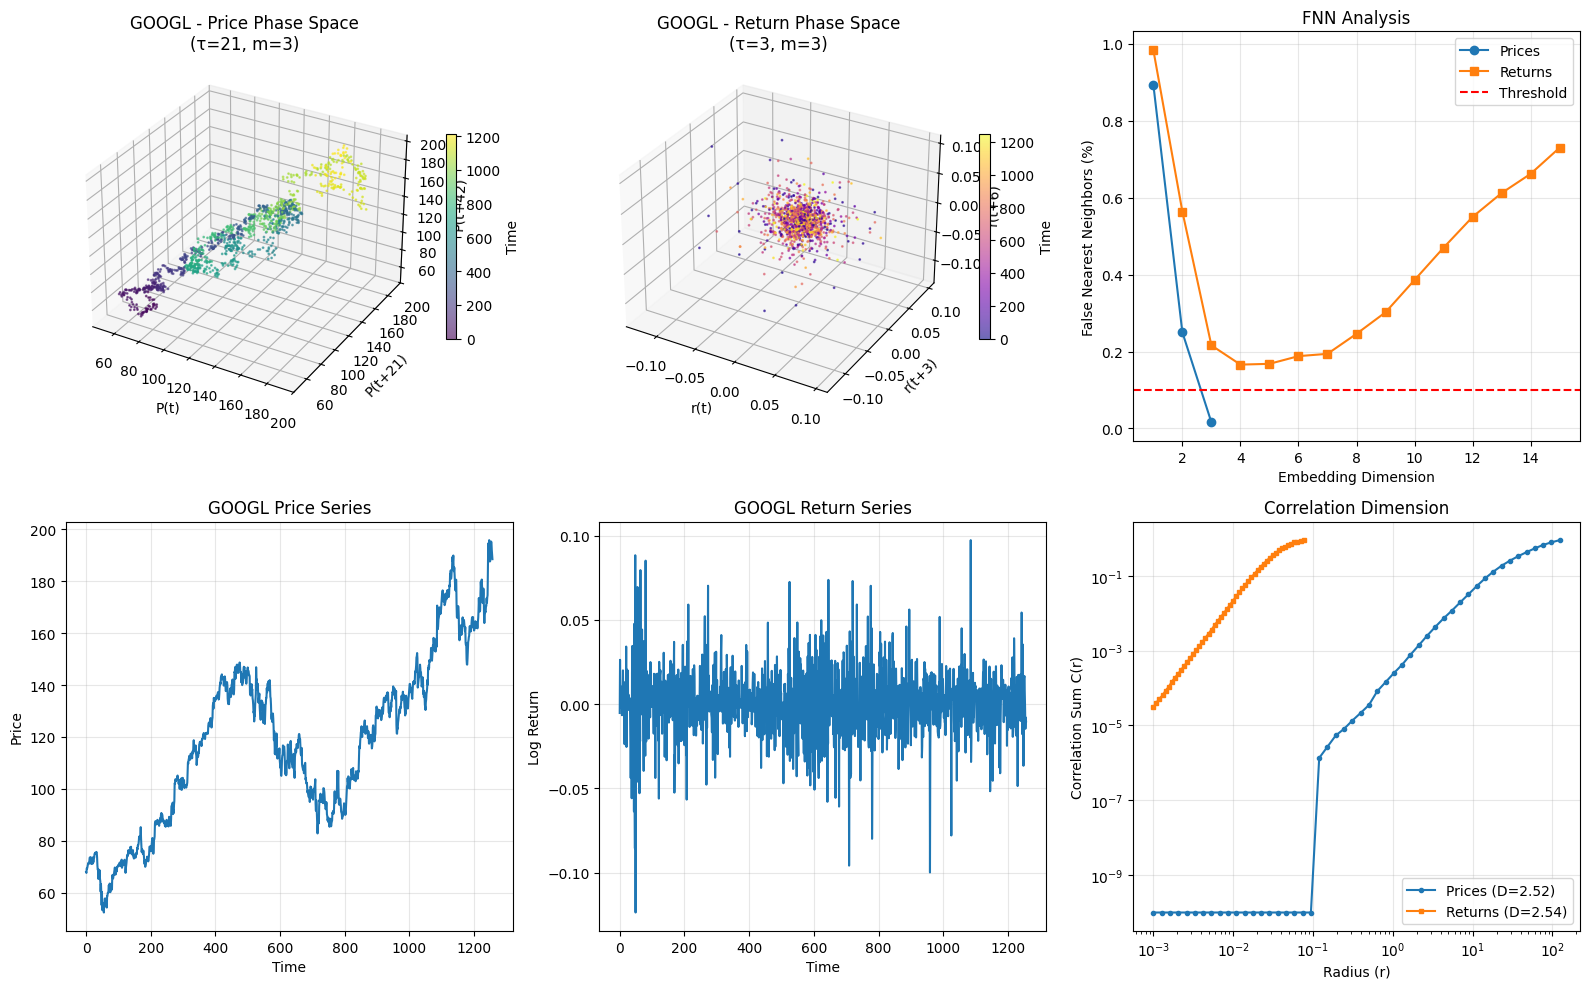


Processing TSLA
Data points: 1258 prices, 1257 returns

--- Time Lag Estimation ---
Prices  - ACF: 93, AMI: 25
Returns - ACF: 1, AMI: 2

--- Embedding Dimension Estimation ---
Prices  - Optimal embedding dimension: 3
Returns - Optimal embedding dimension: 15

--- Building Takens Vectors ---
Price Takens matrix shape: (1208, 3)
Return Takens matrix shape: (1253, 3)

--- Correlation Dimension Estimation ---
Price correlation dimension: 2.297
Return correlation dimension: 2.815


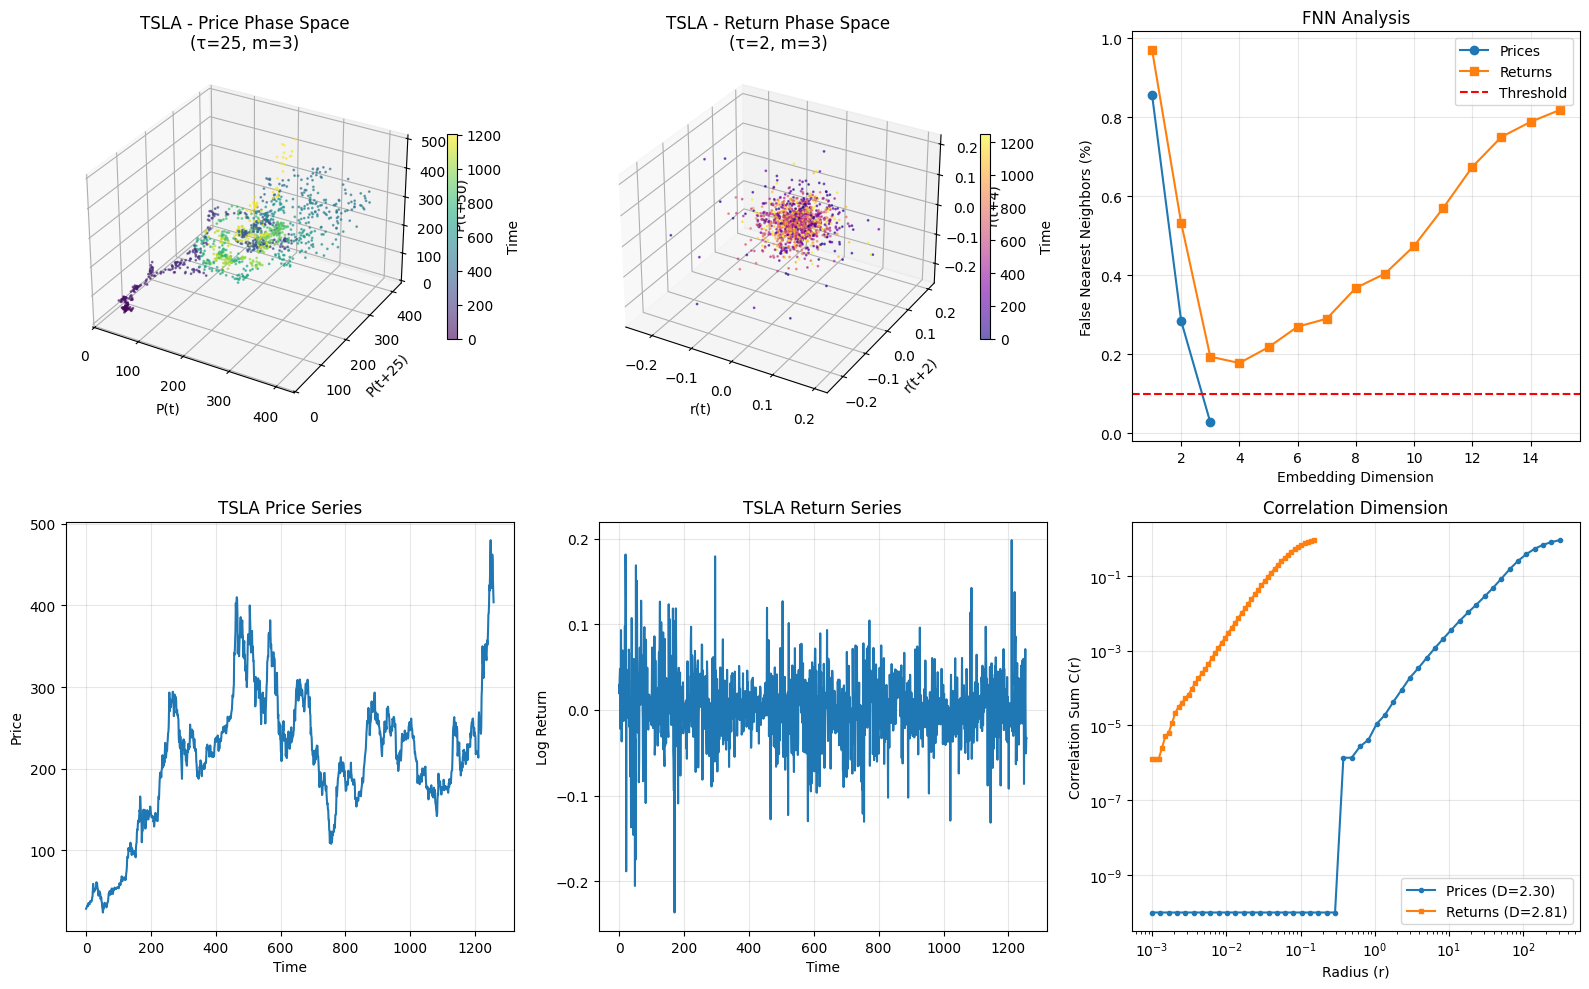


Processing AMZN
Data points: 1258 prices, 1257 returns

--- Time Lag Estimation ---
Prices  - ACF: 1, AMI: 16
Returns - ACF: 1, AMI: 4

--- Embedding Dimension Estimation ---
Prices  - Optimal embedding dimension: 3
Returns - Optimal embedding dimension: 15

--- Building Takens Vectors ---
Price Takens matrix shape: (1226, 3)
Return Takens matrix shape: (1249, 3)

--- Correlation Dimension Estimation ---
Price correlation dimension: 2.539
Return correlation dimension: 2.648


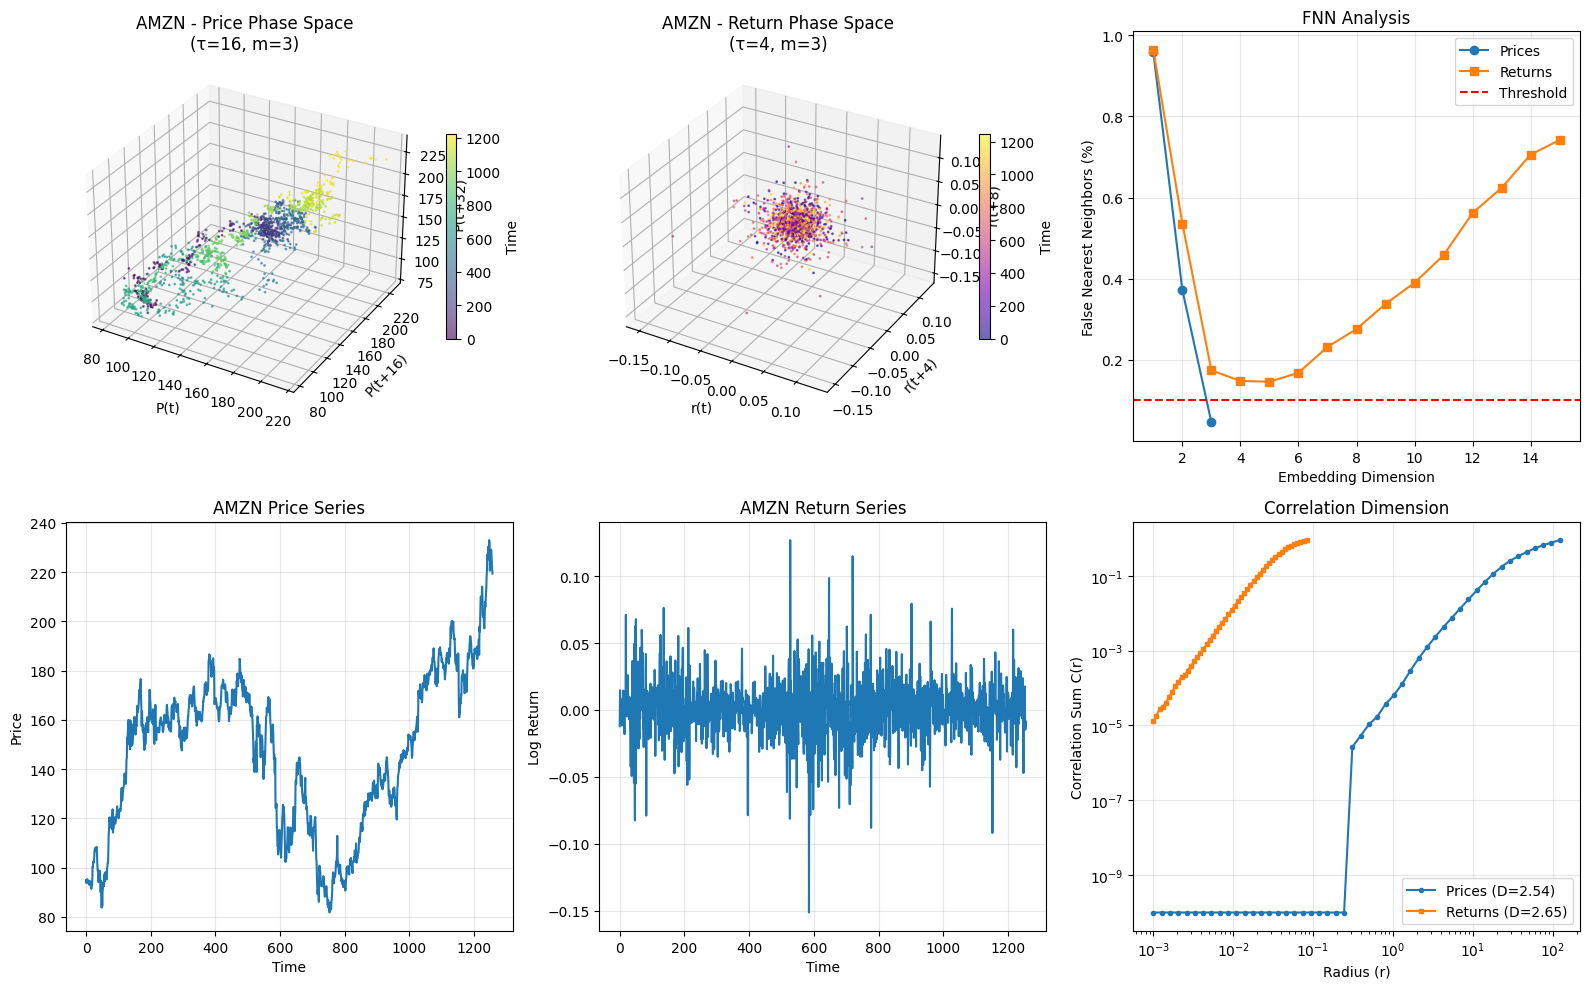


Processing complete!


In [3]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from statsmodels.tsa.stattools import acf
from scipy.stats import entropy

tickers = ["AAPL", "MSFT", "GOOGL", "TSLA", "AMZN"]
start = "2020-01-01"
end = "2025-01-01"
max_lag = 100

def timeLag_acf(series, lag_max=100):
    series = np.array(series).flatten()
    series = series[~np.isnan(series)]
    series = series[~np.isinf(series)]
    
    if len(series) < 10:
        return 1
    
    try:
        nlags = min(lag_max, len(series)//4)
        acf_vals = acf(series, nlags=nlags, fft=True)
        
        first_zero = None
        for i in range(1, len(acf_vals)):
            if acf_vals[i] < 0:
                first_zero = i
                break
        
        if first_zero:
            return first_zero
        
        for i in range(1, len(acf_vals)):
            if acf_vals[i] < 1/np.e:
                return max(1, i)
                
    except:
        return 1
    
    return 1

def timeLag_ami(series, lag_max=100):
    series = np.array(series).flatten()
    series = (series - np.mean(series)) / (np.std(series) + 1e-10)
    
    n_bins = max(10, int(np.sqrt(len(series) / 5)))
    
    def mutual_info(x, y, bins):
        hist_2d, _, _ = np.histogram2d(x, y, bins=bins)
        pxy = hist_2d / (np.sum(hist_2d) + 1e-10)
        px = np.sum(pxy, axis=1) + 1e-10
        py = np.sum(pxy, axis=0) + 1e-10
        
        mi = 0
        for i in range(len(px)):
            for j in range(len(py)):
                if pxy[i, j] > 0:
                    mi += pxy[i, j] * np.log(pxy[i, j] / (px[i] * py[j]))
        return mi
    
    mi_values = []
    for lag in range(1, min(lag_max, len(series)//4)):
        if lag >= len(series):
            break
        mi_val = mutual_info(series[:-lag], series[lag:], n_bins)
        mi_values.append(mi_val)
    
    if len(mi_values) < 3:
        return 1
    
    mi_array = np.array(mi_values)
    
    local_minima = []
    for i in range(1, len(mi_array)-1):
        if mi_array[i] < mi_array[i-1] and mi_array[i] < mi_array[i+1]:
            local_minima.append(i + 1)
    
    if len(local_minima) > 0:
        return local_minima[0]
    
    return np.argmin(mi_array) + 1

def estimateEmbeddingDim(series, time_lag, max_dim=15, threshold=0.1):
    def embed(data, dim, lag):
        n = len(data) - (dim - 1) * lag
        if n <= 0:
            return None
        return np.array([data[i:i + dim * lag:lag] for i in range(n)])
    
    fnn_percentages = []
    
    for dim in range(1, max_dim + 1):
        X1 = embed(series, dim, time_lag)
        X2 = embed(series, dim + 1, time_lag)
        
        if X1 is None or X2 is None or len(X1) < 10 or len(X2) < 10:
            break
        
        rtol = 15.0
        atol = 2.0
        false_neighbors = 0
        n_samples = min(500, len(X1))
        
        for i in range(n_samples):
            distances = np.sqrt(np.sum((X1 - X1[i])**2, axis=1))
            distances[i] = np.inf
            
            nearest_idx = np.argmin(distances)
            
            if nearest_idx >= len(X2):
                continue
            
            d1 = distances[nearest_idx]
            d2 = np.sqrt(np.sum((X2[i] - X2[nearest_idx])**2))
            
            if d1 > 0 and (d2 / d1 > rtol or d2 > atol * np.std(series)):
                false_neighbors += 1
        
        fnn_pct = false_neighbors / n_samples
        fnn_percentages.append(fnn_pct)
        
        if fnn_pct < threshold:
            return dim, fnn_percentages
    
    return max_dim, fnn_percentages

def buildTakens(series, embedding_dim, time_lag):
    n = len(series)
    n_vectors = n - (embedding_dim - 1) * time_lag
    
    if n_vectors <= 0:
        return None
    
    takens_matrix = np.zeros((n_vectors, embedding_dim))
    for i in range(embedding_dim):
        takens_matrix[:, i] = series[i * time_lag : i * time_lag + n_vectors]
    
    return takens_matrix

def corrDim_estimate(series, embedding_dim, time_lag, min_radius=0.001, max_radius=None, n_points=50):
    takens = buildTakens(series, embedding_dim, time_lag)
    
    if takens is None or len(takens) < 10:
        return None, None, None
    
    distances = squareform(pdist(takens, metric='euclidean'))
    
    if max_radius is None:
        max_radius = np.percentile(distances[distances > 0], 90)
    
    radii = np.logspace(np.log10(min_radius), np.log10(max_radius), n_points)
    correlation_sums = []
    
    n = len(takens)
    for r in radii:
        count = np.sum(distances < r) - n
        C_r = count / (n * (n - 1))
        correlation_sums.append(C_r)
    
    correlation_sums = np.array(correlation_sums)
    correlation_sums[correlation_sums <= 0] = 1e-10
    
    log_r = np.log(radii)
    log_C = np.log(correlation_sums)
    
    valid_idx = np.isfinite(log_C) & np.isfinite(log_r)
    
    if np.sum(valid_idx) > 5:
        coeffs = np.polyfit(log_r[valid_idx], log_C[valid_idx], 1)
        corr_dim = coeffs[0]
        return corr_dim, radii, correlation_sums
    
    return None, radii, correlation_sums

for ticker in tickers:
    try:
        print(f"\n{'='*60}")
        print(f"Processing {ticker}")
        print(f"{'='*60}")
        
        data = yf.download(ticker, start=start, end=end, progress=False, auto_adjust=True)
        
        if data.empty or 'Close' not in data.columns:
            print(f"Skipping {ticker}: no data available")
            continue
        
        prices = data['Close'].values
        prices = prices[~np.isnan(prices)]
        
        if len(prices) < 100:
            print(f"Skipping {ticker}: insufficient data")
            continue
        
        log_prices = np.log(prices)
        returns = np.diff(log_prices)
        
        print(f"Data points: {len(prices)} prices, {len(returns)} returns")
        
        print("\n--- Time Lag Estimation ---")
        tau_p_acf = timeLag_acf(prices, max_lag)
        tau_p_ami = timeLag_ami(prices, max_lag)
        tau_r_acf = timeLag_acf(returns, max_lag)
        tau_r_ami = timeLag_ami(returns, max_lag)
        
        print(f"Prices  - ACF: {tau_p_acf}, AMI: {tau_p_ami}")
        print(f"Returns - ACF: {tau_r_acf}, AMI: {tau_r_ami}")
        
        tau_p = tau_p_ami
        tau_r = tau_r_ami
        
        print("\n--- Embedding Dimension Estimation ---")
        emb_dim_p, fnn_p = estimateEmbeddingDim(prices, tau_p, max_dim=15)
        emb_dim_r, fnn_r = estimateEmbeddingDim(returns, tau_r, max_dim=15)
        
        print(f"Prices  - Optimal embedding dimension: {emb_dim_p}")
        print(f"Returns - Optimal embedding dimension: {emb_dim_r}")
        
        m_p = min(emb_dim_p, 3)
        m_r = min(emb_dim_r, 3)
        
        print("\n--- Building Takens Vectors ---")
        Xp = buildTakens(prices, m_p, tau_p)
        Xr = buildTakens(returns, m_r, tau_r)
        
        if Xp is None or Xr is None:
            print(f"Skipping {ticker}: embedding failed")
            continue
        
        print(f"Price Takens matrix shape: {Xp.shape}")
        print(f"Return Takens matrix shape: {Xr.shape}")
        
        print("\n--- Correlation Dimension Estimation ---")
        cd_p, radii_p, corr_p = corrDim_estimate(prices, m_p, tau_p)
        cd_r, radii_r, corr_r = corrDim_estimate(returns, m_r, tau_r)
        
        if cd_p:
            print(f"Price correlation dimension: {cd_p:.3f}")
        if cd_r:
            print(f"Return correlation dimension: {cd_r:.3f}")
        
        fig = plt.figure(figsize=(16, 10))
        
        ax1 = fig.add_subplot(2, 3, 1, projection="3d")
        scatter1 = ax1.scatter(Xp[:,0], Xp[:,1], Xp[:,2], 
                               c=np.arange(len(Xp)), cmap='viridis', s=1, alpha=0.6)
        ax1.set_title(f"{ticker} - Price Phase Space\n(τ={tau_p}, m={m_p})")
        ax1.set_xlabel("P(t)")
        ax1.set_ylabel(f"P(t+{tau_p})")
        ax1.set_zlabel(f"P(t+{2*tau_p})")
        plt.colorbar(scatter1, ax=ax1, label='Time', shrink=0.5)
        
        ax2 = fig.add_subplot(2, 3, 2, projection="3d")
        scatter2 = ax2.scatter(Xr[:,0], Xr[:,1], Xr[:,2], 
                               c=np.arange(len(Xr)), cmap='plasma', s=1, alpha=0.6)
        ax2.set_title(f"{ticker} - Return Phase Space\n(τ={tau_r}, m={m_r})")
        ax2.set_xlabel("r(t)")
        ax2.set_ylabel(f"r(t+{tau_r})")
        ax2.set_zlabel(f"r(t+{2*tau_r})")
        plt.colorbar(scatter2, ax=ax2, label='Time', shrink=0.5)
        
        ax3 = fig.add_subplot(2, 3, 3)
        if fnn_p:
            ax3.plot(range(1, len(fnn_p)+1), fnn_p, 'o-', label='Prices')
        if fnn_r:
            ax3.plot(range(1, len(fnn_r)+1), fnn_r, 's-', label='Returns')
        ax3.axhline(y=0.1, color='r', linestyle='--', label='Threshold')
        ax3.set_xlabel('Embedding Dimension')
        ax3.set_ylabel('False Nearest Neighbors (%)')
        ax3.set_title('FNN Analysis')
        ax3.legend()
        ax3.grid(True, alpha=0.3)
        
        ax4 = fig.add_subplot(2, 3, 4)
        ax4.plot(prices)
        ax4.set_title(f'{ticker} Price Series')
        ax4.set_xlabel('Time')
        ax4.set_ylabel('Price')
        ax4.grid(True, alpha=0.3)
        
        ax5 = fig.add_subplot(2, 3, 5)
        ax5.plot(returns)
        ax5.set_title(f'{ticker} Return Series')
        ax5.set_xlabel('Time')
        ax5.set_ylabel('Log Return')
        ax5.grid(True, alpha=0.3)
        
        ax6 = fig.add_subplot(2, 3, 6)
        if cd_p and corr_p is not None:
            valid = corr_p > 0
            ax6.loglog(radii_p[valid], corr_p[valid], 'o-', label=f'Prices (D={cd_p:.2f})', markersize=3)
        if cd_r and corr_r is not None:
            valid = corr_r > 0
            ax6.loglog(radii_r[valid], corr_r[valid], 's-', label=f'Returns (D={cd_r:.2f})', markersize=3)
        ax6.set_xlabel('Radius (r)')
        ax6.set_ylabel('Correlation Sum C(r)')
        ax6.set_title('Correlation Dimension')
        ax6.legend()
        ax6.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
        
    except Exception as e:
        print(f"Error processing {ticker}: {e}")
        import traceback
        traceback.print_exc()
        continue

print("\n" + "="*60)
print("Processing complete!")
print("="*60)